# 0250061 Tarea 02

Mauro Rogelio Galindo Ibarra

Estado seleccionado: Wyoming (wy)



In [1]:
!pip install fg-data-profiling

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd


In [3]:
url = "https://raw.githubusercontent.com/edavgaun/RCEL_506/refs/heads/main/Module%203/Housing%20states/housing_wy.csv"
url_map_wy = "https://raw.githubusercontent.com/subyfly/topojson/refs/heads/master/us-states/WY-56-wyoming-counties.json"


In [4]:
# y: precio
data = pd.read_csv(url)
data.shape

(187, 21)

In [5]:
# x: zona, tamaño, antiguedad, estado del inmuele, amenidades
data.columns


Index(['Unnamed: 0', 'url', 'region', 'price', 'type', 'sqfeet', 'beds',
       'baths', 'cats_allowed', 'dogs_allowed', 'smoking_allowed',
       'wheelchair_access', 'electric_vehicle_charge', 'comes_furnished',
       'laundry_options', 'parking_options', 'image_url', 'description', 'lat',
       'long', 'state'],
      dtype='object')

# Limpieza inicial de datos

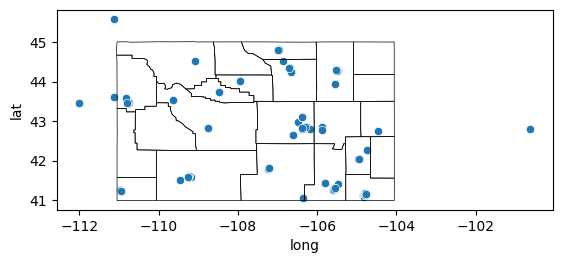

In [6]:
# antes de empezar, quiero verificar que todos los registros tengan coordenadas dentro de WY (que no suceda como con WA)

mapa = gpd.read_file(url_map_wy)

fig, axs = plt.subplots()
mapa.boundary.plot(ax=axs, color="black", linewidth=0.5)
sns.scatterplot(data=data, x="long", y="lat", ax=axs)

plt.show()


In [7]:
# restringimos los datos a los limites de wyoming

print("inicia shape", data.shape)
data = data[
    ((41 <= data.lat ) & (data.lat <= 45)) & 
    ((-111 <= data.long) & (data.long <= -104))
    ]
data.reset_index(drop=True, inplace=True)
print("final shape", data.shape)


inicia shape (187, 21)
final shape (182, 21)


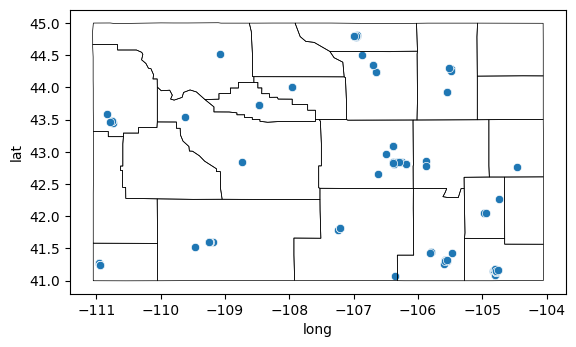

In [8]:
# ya verificamos que la ubicación de todas las propiedades sí esté en los límites de WY
fig, axs = plt.subplots()
mapa.boundary.plot(ax=axs, color="black", linewidth=0.5)
sns.scatterplot(data=data, x="long", y="lat", ax=axs)
plt.show()


In [9]:
# verifico que no hayan datapoints con estado distinto a "wy"
print(data["state"].unique(), data["region"].unique())


['wy'] ['wyoming']


In [10]:
data.dtypes

,0
Unnamed: 0,int64
url,object
region,object
price,int64
type,object
sqfeet,int64
beds,int64
baths,float64
cats_allowed,int64
dogs_allowed,int64


In [11]:
# verificamos que no hayan datos anomalos o NaN's en variables
cols = [c for c in data.columns if c not in ["Unnamed: 0", "image_url", "url", "description", "lat", "long", "price", "sqfeet"]]
for c in cols:
    print(f"{c}\n  ", data[c].unique(), end="\n\n")


region
   ['wyoming']

type
   ['duplex' 'house' 'apartment' 'townhouse' 'cottage/cabin' 'condo' 'flat'
 'manufactured' 'loft']

beds
   [2 3 4 1 0 5]

baths
   [1.  2.  2.5 1.5 3. ]

cats_allowed
   [0 1]

dogs_allowed
   [0 1]

smoking_allowed
   [0 1]

wheelchair_access
   [0 1]

electric_vehicle_charge
   [0 1]

comes_furnished
   [1 0]

laundry_options
   [nan 'w/d hookups' 'w/d in unit' 'laundry in bldg' 'no laundry on site'
 'laundry on site']

parking_options
   ['off-street parking' 'street parking' 'attached garage' 'detached garage'
 'carport' nan 'valet parking' 'no parking']

state
   ['wy']



In [12]:
# eliminamos columnas que no son útiles para nosotros
cols2remove = ["Unnamed: 0", "url", "image_url", "state", "region"]
data.drop(columns=cols2remove, inplace=True)
data


,price,type,sqfeet,beds,baths,cats_allowed,dogs_allowed,smoking_allowed,wheelchair_access,electric_vehicle_charge,comes_furnished,laundry_options,parking_options,description,lat,long
0,1500,duplex,750,2,1.0,0,0,0,0,0,1,NaN,off-street parking,2 Bed/1 Bath upstairs duplex unit in Glenrock....,42.8613,-105.873
1,800,house,1100,3,1.0,0,0,1,0,0,1,w/d hookups,street parking,"FOR RENT THREE BEDROOM ONE BATH, FURNISHED!...",44.2369,-106.656
2,1500,duplex,750,2,1.0,0,0,0,0,0,1,w/d in unit,off-street parking,"2 Bed, 1 Bath ground level unit with W/D in Gl...",42.7803,-105.872
3,900,house,1962,4,2.0,1,1,1,0,0,0,w/d in unit,attached garage,Clean and ready for you to move in! Nice detac...,41.1496,-104.805
4,1145,house,1685,4,2.0,1,1,1,0,0,0,w/d hookups,off-street parking,"Enjoy a Mountain View from a spacious yard, lo...",42.8261,-106.390
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177,850,house,1680,3,2.0,0,0,1,0,0,0,NaN,NaN,This 1680 square foot single family home has 3...,44.3039,-105.524
178,1000,cottage/cabin,500,1,1.0,0,0,0,0,0,1,no laundry on site,NaN,I have a nice fully furnished unit available f...,42.6615,-106.616
179,899,apartment,950,2,1.0,1,1,0,0,0,0,w/d hookups,off-street parking,The Preserve at Rock Springs offers 9 differen...,41.5961,-109.254
180,699,apartment,650,1,1.0,1,1,0,0,0,0,w/d hookups,off-street parking,Don't miss your chance living in the best apar...,41.5961,-109.254


In [13]:
# convertir int64 a binarias

cols_binarias = [
    "cats_allowed",
    "dogs_allowed",
    "smoking_allowed",
    "wheelchair_access",
    "electric_vehicle_charge",
    "comes_furnished"
]

data[cols_binarias] = data[cols_binarias].astype(bool)
data.dtypes


,0
price,int64
type,object
sqfeet,int64
beds,int64
baths,float64
cats_allowed,bool
dogs_allowed,bool
smoking_allowed,bool
wheelchair_access,bool
electric_vehicle_charge,bool


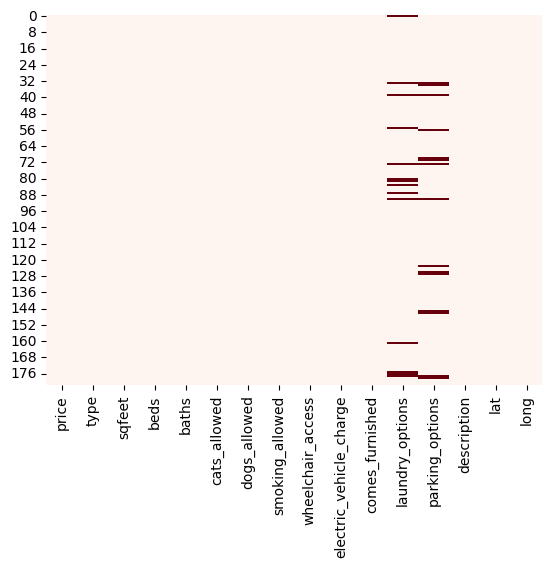

In [14]:
# ahora solo se revisa que únicamente las columnas de laundry y parking tienen Na, 
# pero no son una proporción demasiado grande de los datos no lo tomaremos en cuenta

sns.heatmap(data.isna(), cbar=False, cmap="Reds")
plt.show()


# Exploratory Data Analysis (EDA)


In [15]:
data.describe(include="all").round(2)

,price,type,sqfeet,beds,baths,cats_allowed,dogs_allowed,smoking_allowed,wheelchair_access,electric_vehicle_charge,comes_furnished,laundry_options,parking_options,description,lat,long
count,182.00,182,182.00,182.00,182.00,182,182,182,182,182,182,168,167,182,182.00,182.00
unique,NaN,9,NaN,NaN,NaN,2,2,2,2,2,2,5,7,163,NaN,NaN
top,NaN,apartment,NaN,NaN,NaN,True,True,False,False,False,False,w/d in unit,off-street parking,"Enjoy a Mountain View from a spacious yard, lo...",NaN,NaN
freq,NaN,115,NaN,NaN,NaN,113,118,96,155,178,139,55,111,6,NaN,NaN
mean,985.43,NaN,1142.56,2.23,1.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.59,-106.63
std,446.31,NaN,496.57,0.96,0.55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.23,1.76
min,1.00,NaN,400.00,0.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41.07,-110.96
25%,750.00,NaN,879.00,2.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41.32,-106.98
50%,864.00,NaN,1032.00,2.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.81,-106.19
75%,1145.00,NaN,1285.00,3.00,2.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.69,-105.49


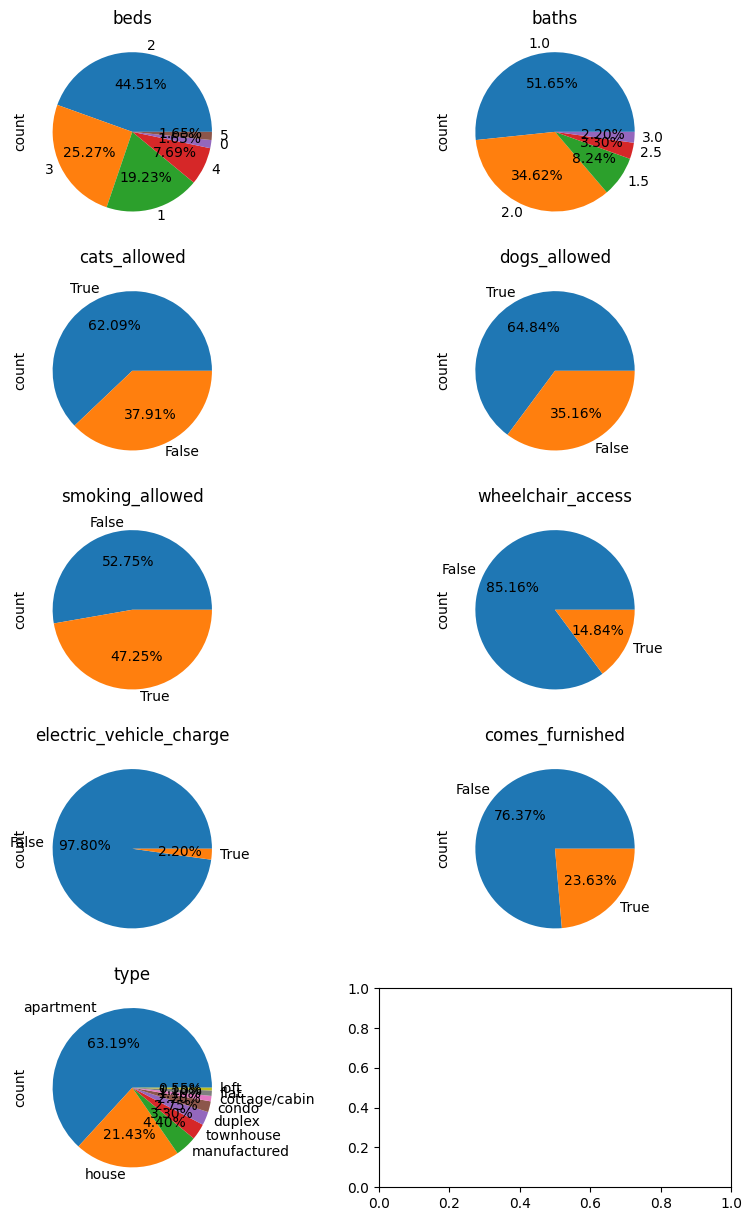

In [16]:
import math
cols = ["beds", "baths", "cats_allowed", "dogs_allowed", "smoking_allowed", "wheelchair_access", "electric_vehicle_charge", "comes_furnished", "type"]
rows = math.ceil(len(cols) / 2)
fig, axs = plt.subplots(rows,2, figsize=(10,15))
rown = 0
coln = 0
for c in cols:
    data[c].value_counts().plot(kind="pie", autopct="%.2f%%", ax=axs[rown,coln])
    axs[rown,coln].set_title(c)
    if coln == 0:
        rown, coln  = rown, 1
    else:
        rown, coln = rown + 1, 0
plt.ylabel("")
plt.show()


Del las gráficas anteriores, el resultado que más destaca es que casi no hay propiedades con carga eléctrica, pero lo mantenemos,
pues sí está disponible podría ser indicador de un mayor precio, por ejemplo.

In [17]:
from data_profiling import ProfileReport
profile = ProfileReport(data, title="Reporte Wyoming")
profile


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:00<00:00, 90.43it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [18]:
# gracias al reporte anterior vemos que hay datos duplicados, pasamos a eliminarlos
data.drop_duplicates(inplace=True)


## Revisión de distribuición de variables

### Distribución de precios

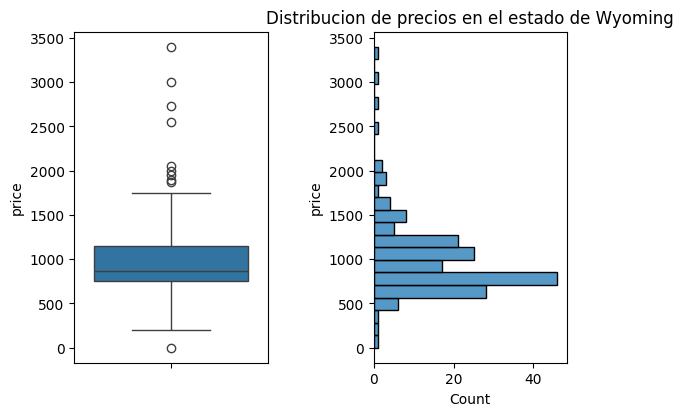

In [19]:
fig, axs = plt.subplots(1,2)

sns.boxplot(data=data, y="price", ax=axs[0], orient="v")
sns.histplot(ax=axs[1], data=data, y="price")

plt.title("Distribucion de precios en el estado de Wyoming")
plt.tight_layout(pad=3)

plt.show()

In [20]:
# eliminamos filas con precios anómalos

data=data[(data.price>200) & (data.price < 2300)]
data.reset_index(drop=True, inplace=True)
data.shape

(167, 16)

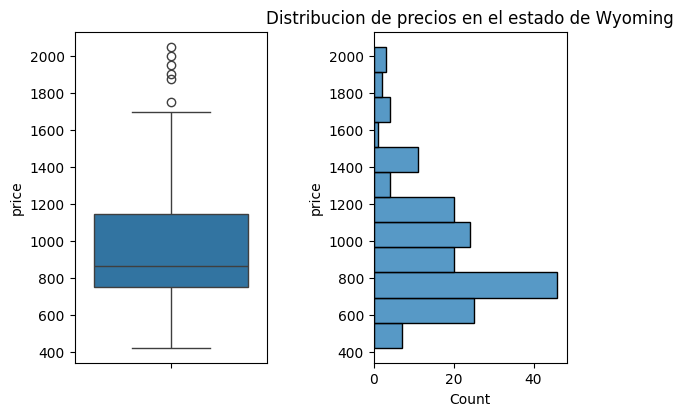

    price       type  sqfeet  beds  baths  cats_allowed  dogs_allowed  \
14    425      house     400     0    1.0          True          True   
46    450  apartment     650     1    1.0          True          True   
65    475  apartment     650     1    1.0          True          True   

    smoking_allowed  wheelchair_access  electric_vehicle_charge  \
14             True              False                    False   
46             True              False                    False   
65             True              False                    False   

    comes_furnished     laundry_options     parking_options  \
14            False  no laundry on site  off-street parking   
46            False     laundry in bldg  off-street parking   
65             True     laundry in bldg  off-street parking   

                                          description      lat     long  
14  one room studio house for rent in Cheyenne.   ...  41.1084 -104.811  
46  Beautiful one bed, one bath apart

In [21]:
# verificamos que las filas resultantes tengan la forma esperada
fig, axs = plt.subplots(1,2)

sns.boxplot(data=data, y="price", ax=axs[0], orient="v")
sns.histplot(ax=axs[1], data=data, y="price")

plt.title("Distribucion de precios en el estado de Wyoming")
plt.tight_layout(pad=3)

plt.show()
byprice = data.sort_values(by="price")
print(byprice.head(3))
print(byprice.tail(3))


In [22]:
data.reset_index(drop=True, inplace=True)

### Distribución de tamaño de propiedad (sqfeet)

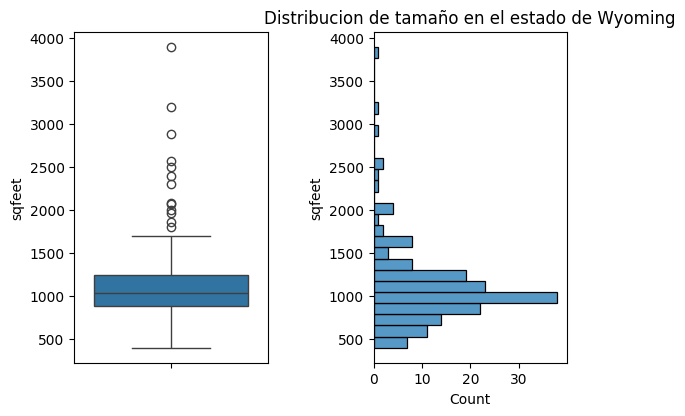

In [23]:
fig, axs = plt.subplots(1,2)

sns.boxplot(data=data, y="sqfeet", ax=axs[0], orient="v")
sns.histplot(ax=axs[1], data=data, y="sqfeet")

plt.title("Distribucion de tamaño en el estado de Wyoming")
plt.tight_layout(pad=3)

plt.show()


In [24]:
# mantenemos datos menores a 35000 porque aunque parecen encontrarse fuera 
# de la regla, sí son algo numerosos, y ya tenemos pocas filas (167 antes 
# de esta celda)

data=data[(data.sqfeet>200) & (data.sqfeet < 3500)]
data.reset_index(drop=True, inplace=True)
data.shape


(166, 16)

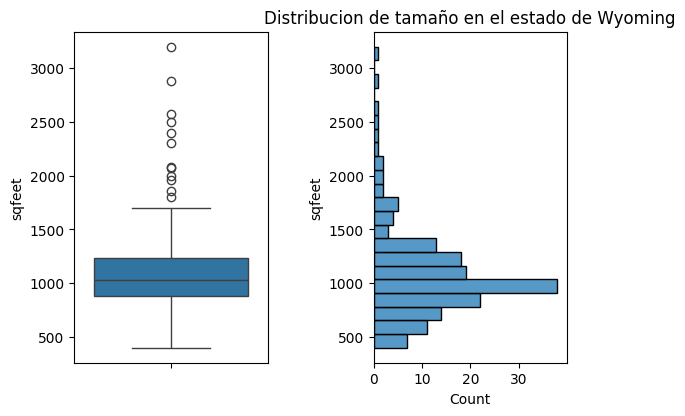

     price       type  sqfeet  beds  baths  cats_allowed  dogs_allowed  \
14     425      house     400     0    1.0          True          True   
156    475  apartment     402     1    1.0         False          True   
165   1685  apartment     470     0    1.0          True          True   

     smoking_allowed  wheelchair_access  electric_vehicle_charge  \
14              True              False                    False   
156            False              False                    False   
165            False              False                    False   

     comes_furnished     laundry_options     parking_options  \
14             False  no laundry on site  off-street parking   
156             True         w/d in unit  off-street parking   
165            False     laundry on site  off-street parking   

                                           description      lat     long  
14   one room studio house for rent in Cheyenne.   ...  41.1084 -104.811  
156  This is a fully fu

In [25]:
# verificamos que las filas resultantes tengan la forma esperada
fig, axs = plt.subplots(1,2)

sns.boxplot(data=data, y="sqfeet", ax=axs[0], orient="v")
sns.histplot(ax=axs[1], data=data, y="sqfeet")

plt.title("Distribucion de tamaño en el estado de Wyoming")
plt.tight_layout(pad=3)

plt.show()
bysqfeet = data.sort_values(by="sqfeet")
print(bysqfeet.head(3))
print(bysqfeet.tail(3))


In [26]:
data.reset_index(drop=True, inplace=True)

## Exploración de Relaciones entre variables

In [27]:
data.columns

Index(['price', 'type', 'sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished', 'laundry_options',
       'parking_options', 'description', 'lat', 'long'],
      dtype='object')

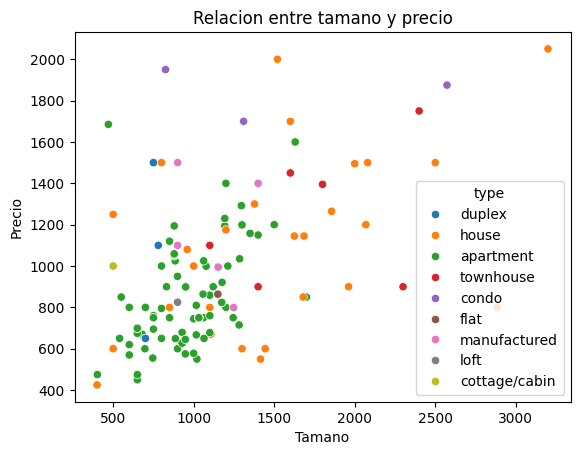

In [28]:
sns.scatterplot(data=data, x="sqfeet", y="price", hue="type")
plt.xlabel("Tamano")
plt.ylabel("Precio")
plt.title("Relacion entre tamano y precio")
plt.show()


In [29]:
# ya vimos antes que la gran mayoria de casas son de estos 4 tipos, por lo que 
# creamos esta columna para reducir el ruido de categorías insignificantes
propiedades = ["apartment", "house", "manufactured", "townhouse"]
data["type2"] = data["type"].apply(lambda x: x if x in propiedades else "other")

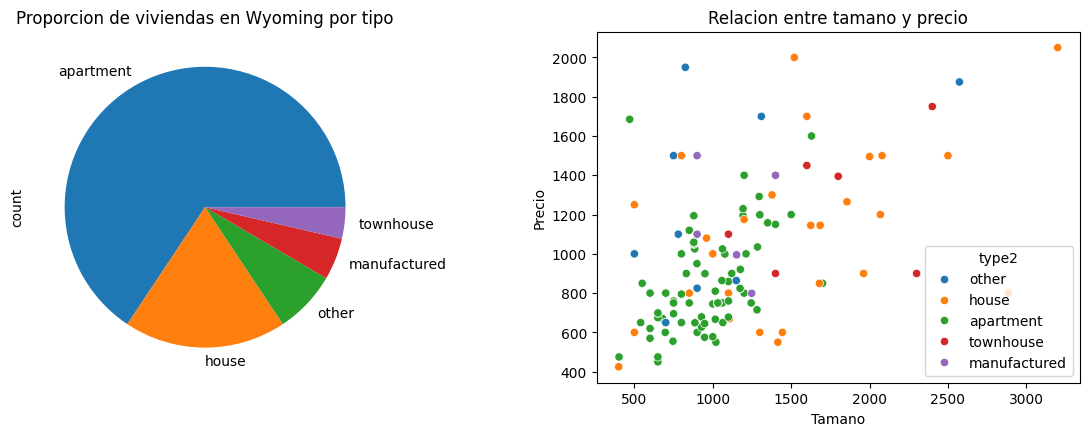

type2
apartment       0.66
house           0.19
other           0.07
manufactured    0.05
townhouse       0.04
Name: proportion, dtype: float64


In [30]:
fig, axs = plt.subplots(1,2, figsize=(12,5))
data["type2"].value_counts().plot(kind="pie", ax=axs[0])
axs[0].set_title("Proporcion de viviendas en Wyoming por tipo")


sns.scatterplot(data=data, x="sqfeet", y="price", 
                #style=type2
                #size="sqfeet",
                hue="type2",
                ax=axs[1]
                )
axs[1].set_xlabel("Tamano")
axs[1].set_ylabel("Precio")
axs[1].set_title("Relacion entre tamano y precio")


plt.tight_layout(pad=3)
plt.show()
print(data["type2"].value_counts(normalize=True).round(2))

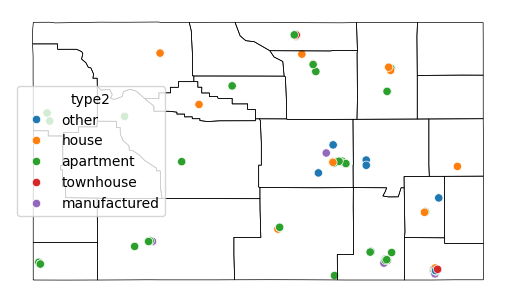

In [31]:
# la mayoria son departamentos, pero podemos ver que las casas pueden mantener
# su precio bajo incluso con tamanos mayores
# ahora revisaremos su distribucion geografica 

fig, axs = plt.subplots()
mapa.boundary.plot(color="black", linewidth=0.5, ax=axs)
sns.scatterplot(data=data, x="long", y="lat", ax=axs, hue="type2")
plt.axis("off")
plt.show()


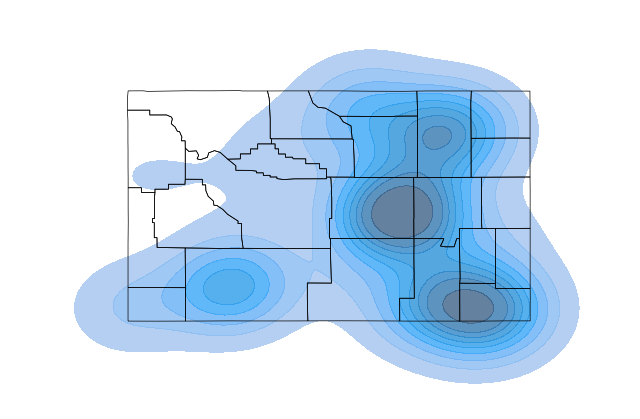

In [32]:
# primero exploramos la distribucion general, vemos que las propiedades ofertadas
# estan centradas en centros urbanos
fig, axs = plt.subplots(figsize=(8,6))
mapa.boundary.plot(color="black", linewidth=0.5, ax=axs
                    )
sns.kdeplot(data=data, x="long", y="lat", ax=axs,
            fill=True, alpha=0.8
            )
plt.axis("off")
plt.show()


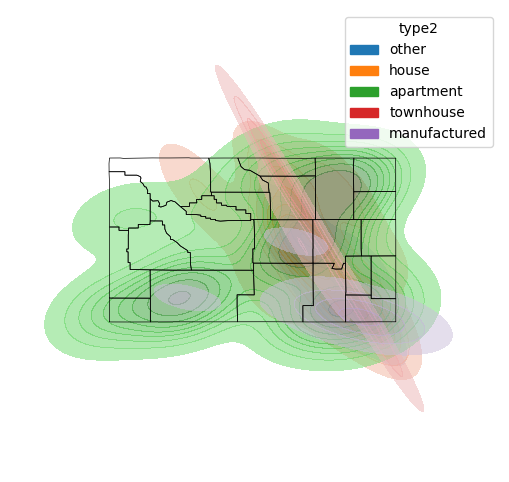

In [33]:
# observaremos alguna diferencia por tipos de propiedades?

fig, axs = plt.subplots(figsize=(8,6))
mapa.boundary.plot(color="black", linewidth=0.5, ax=axs
                    )
sns.kdeplot(data=data, x="long", y="lat", ax=axs,
            fill=True, alpha=0.5, hue="type2"
            )
plt.axis("off")
plt.show()

# como es esperado, apartementos hay en centros urbanos, pero 
# parece que casas listadas en craigslist tampoco tienen una distribucion
# mucho mayor, 


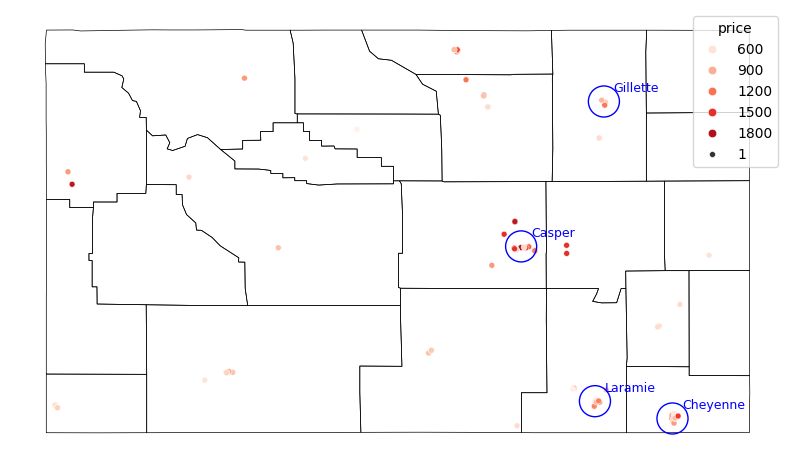

In [34]:
ciudades_wy = [
    ("Cheyenne", 41.139, -104.820),
    ("Casper", 42.850, -106.325),
    ("Gillette", 44.291, -105.502),
    ("Laramie", 41.311, -105.591),
]

fig, axs = plt.subplots(figsize=(10, 8))

mapa.boundary.plot(color="black", linewidth=0.5, ax=axs)

sns.scatterplot(data=data, x="long", y="lat", ax=axs, hue="price", palette="Reds", size=1)

# marcamos un perimetro aproximado de las ciudades mas grandes de WY 
for nombre_ciudad, lat, lon in ciudades_wy:
    axs.scatter(lon, lat, s=500, facecolors="none", edgecolors="blue", linewidths=1, zorder=5)
    axs.annotate(nombre_ciudad, xy=(lon, lat), xytext=(7, 7), textcoords="offset points", fontsize=9, 
         color="blue", zorder=7 
        )

plt.axis("off")
plt.show()

# aqui verificamos que ciertamente el listado tiene la mayoria de propiedades en ciudades grandes


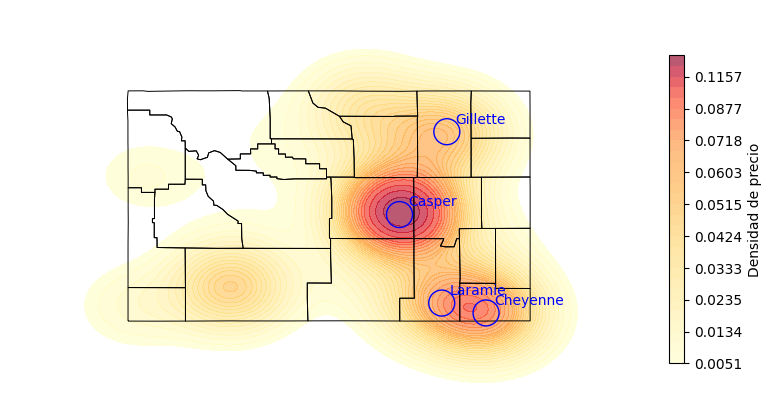

In [35]:
# ahora queremos ver como se distribuyen los precios, y observamos que en Casper los precios suelen ser mas altos
fig, axs = plt.subplots(figsize=(10, 8))

mapa.boundary.plot(color="black", linewidth=0.7, ax=axs)

sns.kdeplot(data=data, x="long", y="lat", weights=data["price"], cmap="YlOrRd", fill=True,
    alpha=0.65, levels=30, cbar=True, cbar_kws={"label": "Densidad de precio", "shrink": 0.5}, ax=axs)

for ciudad, lat, lon in ciudades_wy:
    axs.scatter(lon, lat, s=350, facecolors="none", edgecolors="blue", zorder=5)
    axs.annotate(ciudad, xy=(lon, lat), xytext=(6, 6), textcoords="offset points", color="blue", zorder=7)

plt.axis("off")
plt.show()


# Modelo de Machine Learning

In [36]:
# 1. seleccionamos modelo de regresion lineal multiple
from sklearn.linear_model import LinearRegression
# 2. creamos modelo
model_s = LinearRegression()


In [37]:
# 3. seleccionamos datos para predecir y con que predecir
X = ["sqfeet"]
y = "price"
# 4. entrenamos
model_s.fit(data[X], data[y])


LinearRegression()

In [38]:
# 5. métricas del modelo
model_s.score(data[X], data[y])

# obtenemos una score inicial algo baja 0.2520122031759383


0.2520122031759383

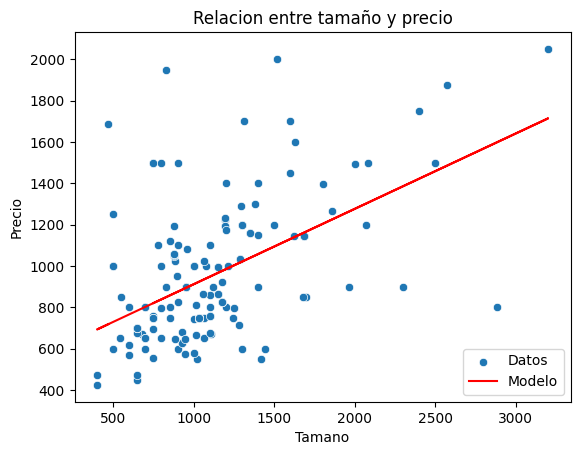

In [39]:
# como ya habiamos visto antes, sqfeet no predice directamente el precio, hay mas variables
y_pred = model_s.predict(data[X])

sns.scatterplot(data=data, x="sqfeet", y="price")
plt.plot(data[X], y_pred, color="red")
plt.xlabel("Tamano")
plt.ylabel("Precio")
plt.legend(["Datos", "Modelo"])
plt.title("Relacion entre tamaño y precio")
plt.show()


Evaluacion del modelo

**Interpretacion de $R^2$**

- Buen resultado: 1 - 0.75
- Resultado Medio: 0.75 - 0.5
- Resultado Bajo: 0.5 - 0.25
- Resultado Nulo: 0.25 - 0


In [40]:
data.dtypes

,0
price,int64
type,object
sqfeet,int64
beds,int64
baths,float64
cats_allowed,bool
dogs_allowed,bool
smoking_allowed,bool
wheelchair_access,bool
electric_vehicle_charge,bool


In [41]:
# creando un modelo de regresion lineal multiple con solo valores numericos/booleanos (antes del one hot encoding)
model_s = LinearRegression()
X = ["sqfeet", "beds", "baths", "cats_allowed", "dogs_allowed", "smoking_allowed", "wheelchair_access", "electric_vehicle_charge", "comes_furnished", "lat", "long"]
y = "price"
model_s.fit(data[X], data[y])
model_s.score(data[X], data[y])



0.36601373651547564

In [42]:
# One Hot Encoding de todas las variables categoricas, vamos a intentar aprovechar todas
# pues tal vez en cierto tipo de lugar sean determinantes para disminuir/aumentar precio
data = pd.get_dummies(data, columns=["type2", "laundry_options", "parking_options"])
data.columns


Index(['price', 'type', 'sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished', 'description', 'lat',
       'long', 'type2_apartment', 'type2_house', 'type2_manufactured',
       'type2_other', 'type2_townhouse', 'laundry_options_laundry in bldg',
       'laundry_options_laundry on site', 'laundry_options_no laundry on site',
       'laundry_options_w/d hookups', 'laundry_options_w/d in unit',
       'parking_options_attached garage', 'parking_options_carport',
       'parking_options_detached garage', 'parking_options_no parking',
       'parking_options_off-street parking', 'parking_options_street parking',
       'parking_options_valet parking'],
      dtype='object')

In [43]:
# creando un modelo de regresion lineal multiple
model_s = LinearRegression()
# ya tenemos type2 y description no nos serviria, ademas de prices
X = [c for c in data.columns if c not in ("type", "description", "price")]
y = "price"
model_s.fit(data[X], data[y])
model_s.score(data[X], data[y])

# mejora considerablemente el modelo


0.5573846002518772

In [44]:
data.description.head(15)
# vemos que en la descripcion hay palabras clave como:
# mountain view, clean, new, security deposit, studio house


,description
0,2 Bed/1 Bath upstairs duplex unit in Glenrock....
1,"FOR RENT THREE BEDROOM ONE BATH, FURNISHED!..."
2,"2 Bed, 1 Bath ground level unit with W/D in Gl..."
3,Clean and ready for you to move in! Nice detac...
4,"Enjoy a Mountain View from a spacious yard, lo..."
5,Large 2 bedroom garden-level basement apartmen...
6,$500 Security Deposit with Approved Credit Gra...
7,"Enjoy a Mountain View from a spacious yard, lo..."
8,"Enjoy a Mountain View from a spacious yard, lo..."
9,"Enjoy a Mountain View from a spacious yard, lo..."


## Probamos Bag of Words y TfidVectorizer

Inicialmente use la implementacion de la clase, pero para mejorar el rendimiento, pasé a usar Tfid:
- Usamos Tfid para tomar en cuenta la presencia de cada palabra relativa localmente y no solo en lo global
ademas, palabras muy frecuentes pierden valor, pues son tan comunes que dejan de dar significado nuevo al 
modelo, mientra que en BOW siguen teniendo mayor importancia

In [45]:
from sklearn.feature_extraction.text import CountVectorizer
import re

# Define a cleaning function
def clean_text(text):
    # Remove words with numbers or special characters, and words shorter than 4 characters
    words = re.findall(r'\b[a-zA-Z]{4,}\b', text.lower())
    return ' '.join(words)
# Apply the cleaning function to the 'description' column
data['cleaned_description'] = data['description'].apply(clean_text)
# Initialize CountVectorizer
vectorizer = CountVectorizer()
# Fit and transform the cleaned 'description' column to create the BoW model
bow_matrix = vectorizer.fit_transform(data['cleaned_description'])
# Display the shape of the resulting BoW matrix
print(f"Shape of Bag-of-Words matrix: {bow_matrix.shape}")
# Display some of the feature names (words) learned by the vectorizer
print("First 20 feature names (after cleaning):")
print(vectorizer.get_feature_names_out()[:20])

Shape of Bag-of-Words matrix: (166, 1671)
First 20 feature names (after cleaning):
['able' 'about' 'above' 'absolutely' 'accept' 'acceptance' 'accepted'
 'accepting' 'access' 'accessibility' 'accessible' 'accommodate'
 'accommodation' 'accurate' 'aces' 'acre' 'acreage' 'active' 'activities'
 'addition']


In [46]:
from IPython.display import display, HTML

display(HTML(f"""
<div style="max-height: 300px; overflow-y: auto; border: 1px solid #ddd; padding: 5px;">
    {data[["description"]].to_html()}
</div>
"""))


,description
0,"2 Bed/1 Bath upstairs duplex unit in Glenrock. Utilities & internet provided. Furnished, includes kitchenware, linens, & bi-weekly cleaning. No pets, no smoking, no exceptions. Month-to-month rental terms, $1500 p/month, $500 deposit."
1,"FOR RENT THREE BEDROOM ONE BATH, FURNISHED! Walk-to town and city park in minutes.Beautiful west sunset view of the Big Hornn Mtn. Feels more like a cabin/cottage... Month to Month. CALL MIKE show contact info . Available December 15th."
2,"2 Bed, 1 Bath ground level unit with W/D in Glenrock. Utilities & internet provided. Furnished, includes kitchenware, linens, & bi-weekly cleaning. Clean and convenient. No pets, no smoking, no exceptions. Month-to-month rental terms, $1500 p/month, $500 deposit."
3,"Clean and ready for you to move in! Nice detached garage or workshop, and 1 car attached garage to get in out of the weather. 4 bedrooms, 2 bathrooms, metal siding, storage shed, newer Pella windows. We invite you to come take a look at this great home for you and your family!"
4,"Enjoy a Mountain View from a spacious yard, located on the west side of town. Come build a snowman outside or entertain guests inside a spacious 4bd 2ba house for 1145/mo. *Income Restrictions Apply* 760 Landmark Dr. Casper, Wy 82609 1 person - $33,480 2 person - $38,280 3 person - $43,080 4 person - $47,820 5 person - $51,660 6 person - $55,500 7 person - $59,340 8 person - $63,180 What is included? LaundryÂ Â Location: Private In-Home/In-SuiteOutdoor Spaces:Â Â Use of Yard: Yes, West FacingÂ Â BBQ Allowed: YesBuilding DetailsÂ Â Elevator: NoÂ Â Wheelchair Access: Yes"
5,"Large 2 bedroom garden-level basement apartment for rent. $800 rent plus $200 utilities per month. $800 deposit. Fireplace, off-street parking, shared laundry room with W/D, fenced back yard, lots of storage/closet space. Well-behaved spayed/neutered pets will be considered with an additional $100 deposit. About 1 mile north of UW. NO smoking/drugs/parties. 6 month to 1 year renewable lease."
6,"$500 Security Deposit with Approved Credit Granite 550 550 Granite Peak Dr, Casper, WY, 82609Interested in more information? See link below:http://EchelonPropertyGroup.touraptnow.com/i00770 Call Now: show contact info x 17OR Text 17 to show contact info to text with us.Apartments for Rent in Casper, WY! This is a 2 Bedroom, 2 Bath, approximately 1193 Sq. Ft. At Granite 550, there are many great ways to spend your day without leaving the neighborhood with our many impressive onsite amenities. Entertain guests at the pool, park, or one of the community spaces. Year-round events bring excitement to our neighborhood and create a true sense of community. Onsite professional management services are also available 24/7, so you know you will always be taken care of. Features - Beautiful 1-, 2-, and 3-Bedroom Apartment Homes with Private Entries - Plank-Wood Style Flooring - In-Home Washer & Dryer - Modern Kitchens with Granite Countertops, Islands*, and Stainless-Steel Appliances - Grand 12-Foot Tall Ceilings - Spacious Master Bedrooms with Walk-In Closets and Double Vanity Sinks - Private Patio/Balcony - Fully Furnished Homes Available* - Central Heat & Air Conditioning *In Select Homes Community Amenities - Private Oversized Detached Garages Available with Power for Engine Block Heater, Power Tools, and More - Resident Clubhouse Featuring a Business Center, TV Lounge & Rentable Party Space with a Pool Table & Foosball Table - Non-Smoking Community - Pet-Friendly Community with Dog Park & Pampered Pet Wash Station - Sparking Heated Swimming Pool with Poolside Pavilion with Community BBQ Grills & Picnic Area - 24-Hour Fitness Center with WellBeats OnDemand Virtual Classes, & TRX System - Onsite Guest Suite Available - Covered Car Center Including Vacuum Station - Conference Room with AV Connections - Community Playground - Outdoor Fire-Pit Lounge Area - On-Site Management with Courtesy Package Acceptance, 24-Hour Emergency Maintenance, and On-Call C

In [47]:
# selecciono las columans nuevas a mano
new_cols = ["community", "center", "amenities", "pool", "fitness", "deposit", "new", "modern", "private", "renovated", "downtown", "remodeled", "garden", "garage"]
for col in new_cols:
    data[col] = data.description.apply(lambda x: 1 if col in x.lower() else 0)
    

In [48]:
data

,price,type,sqfeet,beds,baths,cats_allowed,dogs_allowed,smoking_allowed,wheelchair_access,electric_vehicle_charge,...,fitness,deposit,new,modern,private,renovated,downtown,remodeled,garden,garage
0,1500,duplex,750,2,1.0,False,False,False,False,False,...,0,1,0,0,0,0,0,0,0,0
1,800,house,1100,3,1.0,False,False,True,False,False,...,0,0,0,0,0,0,0,0,0,0
2,1500,duplex,750,2,1.0,False,False,False,False,False,...,0,1,0,0,0,0,0,0,0,0
3,900,house,1962,4,2.0,True,True,True,False,False,...,0,0,1,0,0,0,0,0,0,1
4,1145,house,1685,4,2.0,True,True,True,False,False,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,850,house,1680,3,2.0,False,False,True,False,False,...,0,0,0,0,0,0,0,0,0,0
162,1000,cottage/cabin,500,1,1.0,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
163,899,apartment,950,2,1.0,True,True,False,False,False,...,1,0,0,0,0,0,0,0,1,0
164,699,apartment,650,1,1.0,True,True,False,False,False,...,1,0,0,0,0,0,0,0,0,0


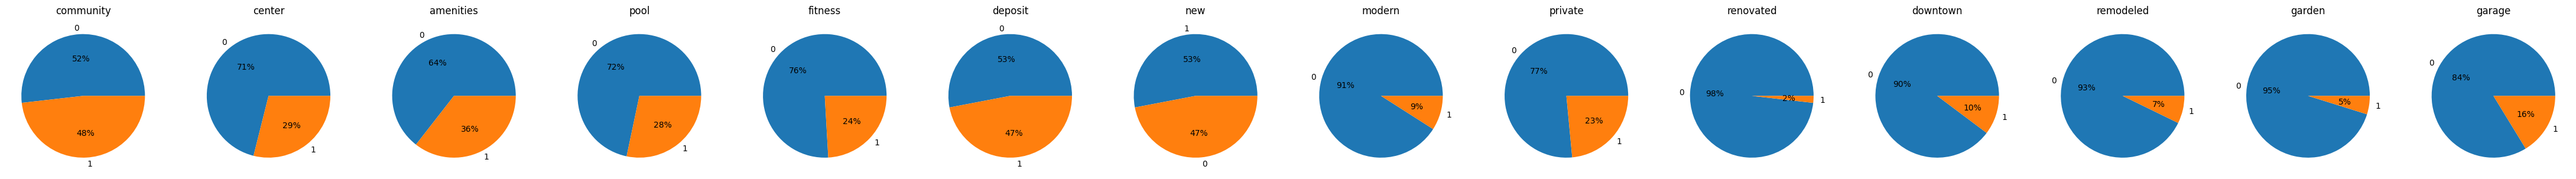

In [49]:
fig, axes = plt.subplots(1, len(new_cols), figsize=(4 * len(new_cols), 4))

for col, ax in zip(new_cols, axes):
    data[col].value_counts().plot(kind="pie", ax=ax, autopct="%1.0f%%")
    ax.set_title(col)
    ax.set_ylabel("")

plt.show()


In [50]:
model = LinearRegression()

X = [c for c in data.columns if c not in {"type", "description", "price", "cleaned_description"}]


y = "price"
model.fit(data[X], data[y])
model.score(data[X], data[y])

# se obtiene mejora, pero no es muy significativa


0.6128288047821373

In [51]:
from sklearn.feature_extraction.text import TfidfVectorizer
# ahora vamos a intentar c on Tfidf, tomando en cuenta las 25 palabras más relevantes
tfidf = TfidfVectorizer(
    stop_words="english",
    token_pattern=r"\b[a-zA-Z]{3,}\b",
    max_features=25,
    min_df=5
)
tfidf_matrix = tfidf.fit_transform(data["description"].fillna(""))

tfidf_cols = [f"tfidf_{w}" for w in tfidf.get_feature_names_out()]
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_cols, index=data.index)

base_features = [c for c in data.columns if c not in ("type", "description", "price", "cleaned_description")]
X_cols = base_features + tfidf_cols

data_with_tfidf = pd.concat([data[base_features], tfidf_df], axis=1)

y = data["price"]
model = LinearRegression()
model.fit(data_with_tfidf[X_cols], y)

print(model.score(data_with_tfidf[X_cols], y))
# obtenemos uan considerable mejora: 0.7824590345220489


0.7882708289875977


In [52]:
# curiosamente, muchas palabras relevantes, se supone ya vendrían en las columnas de información originales
# en un trabajo posterior podríamos hacer una revisión más exhaustiva, con más feautres de Tfidf, pero 
# eliminando aquellas que ya deberían estar cubiertas en las columnas originales
print(tfidf_cols)

['tfidf_apartment', 'tfidf_apartments', 'tfidf_area', 'tfidf_available', 'tfidf_beautiful', 'tfidf_bedroom', 'tfidf_center', 'tfidf_community', 'tfidf_contact', 'tfidf_deposit', 'tfidf_features', 'tfidf_friendly', 'tfidf_hills', 'tfidf_home', 'tfidf_homes', 'tfidf_info', 'tfidf_laundry', 'tfidf_living', 'tfidf_month', 'tfidf_new', 'tfidf_pet', 'tfidf_pets', 'tfidf_rent', 'tfidf_room', 'tfidf_spacious']


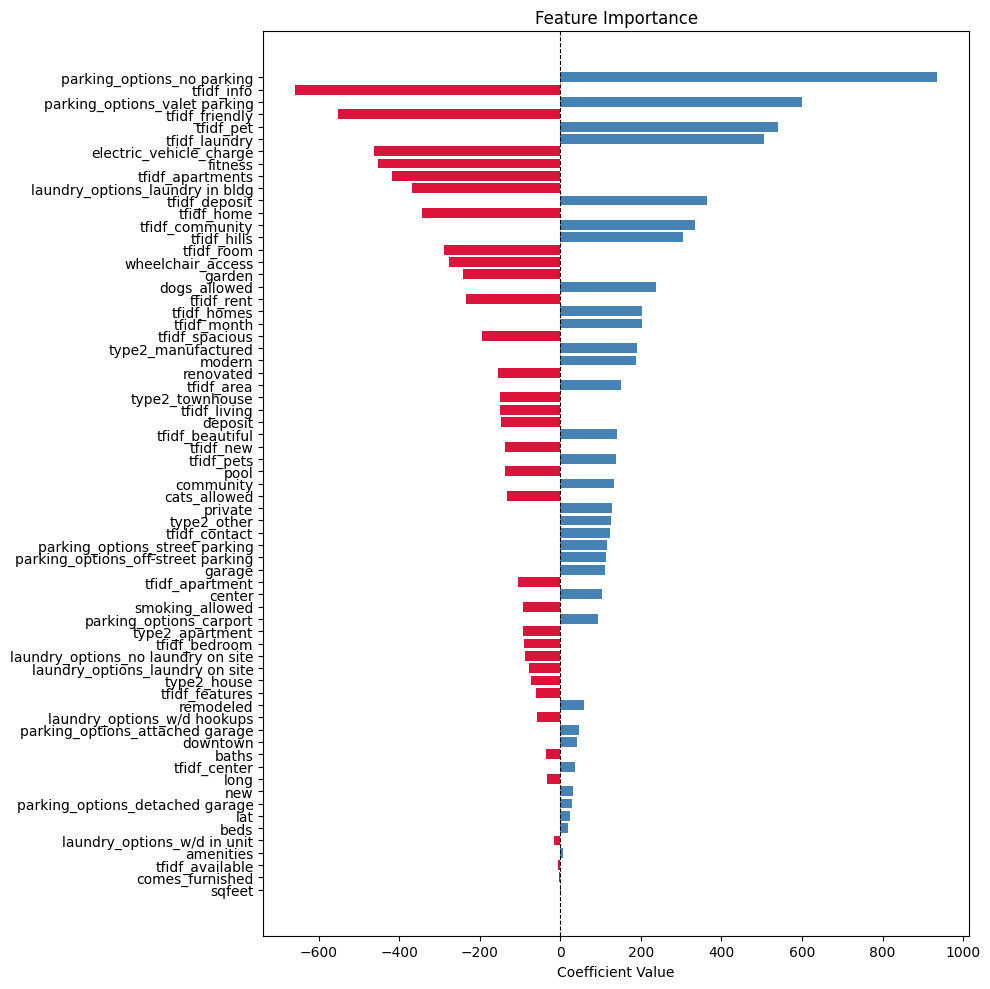

In [53]:
fi = pd.DataFrame({"Feature": X_cols, "Coefficient": model.coef_})
fi["Abs"] = fi["Coefficient"].abs()
fi = fi.sort_values("Abs", ascending=True)

colors = ["steelblue" if c >= 0 else "crimson" for c in fi["Coefficient"]]

plt.figure(figsize=(10, 10))
plt.barh(fi["Feature"], fi["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
plt.xlabel("Coefficient Value")
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

